In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os
if not os.path.exists('/content/pumpkin_data'):
    !unzip -q "/content/drive/MyDrive/Original Dataset.zip" -d /content/pumpkin_data

Mounted at /content/drive


In [2]:
# Settings from Bhuria et al. (2026) - DualFusion-CBAM-Stochastic
# Reference [9]: "AI-powered detection of pumpkin leaf diseases using DualFusion-CBAM-stochastic for yield protection and precision agriculture"
# Architecture combines DenseNet-121 & EfficientNet-B3 with CBAM attention & stochastic depth (Reached 96% Acc, F1 0.96)
import json, time, random, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import transforms, datasets, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support

IMG, BS, LR, EPOCHS = 224, 8, 1e-5, 50      # 224x224, batch 8, lr 1e-5, 50 epochs
STEP, GAMMA = 5, 0.1                         # lr x0.1 every 5 epochs
WD = 1e-4                                    # Adam weight decay
SPLIT_SEED, SEED = 42, 42                    # SEED: change for repeat runs
OUT = '/content/drive/MyDrive/pumpkin_runs'
os.makedirs(OUT, exist_ok=True)
RUN = f'dualfusion_cbam_stochastic_seed{SEED}'

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu'); print(device)

cuda


In [3]:
def find_root(base):
    for r, dirs, _ in os.walk(base):
        if len(dirs) == 5 and all(any(f.lower().endswith(('.jpg','.jpeg','.png')) for f in os.listdir(os.path.join(r, d))) for d in dirs):
            return r
ROOT = find_root('/content/pumpkin_data')
full = datasets.ImageFolder(ROOT); classes = full.classes
paths  = [os.path.relpath(p, ROOT) for p, _ in full.samples]
labels = np.array([y for _, y in full.samples])

# 80-10-10 Stratified Split
split_file = f'{OUT}/split_801010_seed{SPLIT_SEED}.json'
if os.path.exists(split_file):
    split = json.load(open(split_file))
else:
    idx = np.arange(len(paths))
    tr, tmp = train_test_split(idx, test_size=0.20, stratify=labels, random_state=SPLIT_SEED)
    va, te = train_test_split(tmp, test_size=0.50, stratify=labels[tmp], random_state=SPLIT_SEED)
    split = dict(train=[paths[i] for i in tr], val=[paths[i] for i in va], test=[paths[i] for i in te])
    json.dump(split, open(split_file, 'w'))

tf = transforms.Compose([transforms.Resize((IMG, IMG)), transforms.ToTensor(),
                         transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
ds = datasets.ImageFolder(ROOT, transform=tf)
p2i = {p: i for i, p in enumerate(paths)}
sub = lambda k: Subset(ds, [p2i[p] for p in split[k]])
g = torch.Generator(); g.manual_seed(SEED)
train_loader = DataLoader(sub('train'), batch_size=BS, shuffle=True, num_workers=2, generator=g)
val_loader   = DataLoader(sub('val'),   batch_size=BS, num_workers=2)
test_loader  = DataLoader(sub('test'),  batch_size=BS, num_workers=2)
print(classes, {k: len(v) for k, v in split.items()})

['Bacterial Leaf Spot', 'Downy Mildew', 'Healthy Leaf', 'Mosaic Disease', 'Powdery_Mildew'] {'train': 1600, 'val': 200, 'test': 200}


In [4]:
# --- CBAM: Channel Attention Module ---
class ChannelAttention(nn.Module):
    def __init__(self, in_planes, reduction=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        reduced = max(8, in_planes // reduction)
        self.fc = nn.Sequential(
            nn.Linear(in_planes, reduced, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(reduced, in_planes, bias=False)
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        b, c, _, _ = x.size()
        avg_out = self.fc(self.avg_pool(x).view(b, c)).view(b, c, 1, 1)
        max_out = self.fc(self.max_pool(x).view(b, c)).view(b, c, 1, 1)
        return x * self.sigmoid(avg_out + max_out)

# --- CBAM: Spatial Attention Module ---
class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size=kernel_size, padding=kernel_size // 2, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        scale = torch.cat([avg_out, max_out], dim=1)
        return x * self.sigmoid(self.conv(scale))

# --- CBAM Block ---
class CBAM(nn.Module):
    def __init__(self, in_planes, reduction=16, kernel_size=7):
        super().__init__()
        self.ca = ChannelAttention(in_planes, reduction)
        self.sa = SpatialAttention(kernel_size)

    def forward(self, x):
        return self.sa(self.ca(x))

# --- Stochastic Depth (Drop Path) ---
class StochasticDepth(nn.Module):
    def __init__(self, drop_prob=0.2):
        super().__init__()
        self.drop_prob = drop_prob

    def forward(self, x):
        if not self.training or self.drop_prob == 0.0:
            return x
        keep_prob = 1.0 - self.drop_prob
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        random_tensor = keep_prob + torch.rand(shape, dtype=x.dtype, device=x.device)
        random_tensor.floor_()
        return (x / keep_prob) * random_tensor

# --- DualFusion-CBAM-Stochastic Architecture ---
class DualFusionCBAMStochastic(nn.Module):
    def __init__(self, num_classes=5, drop_prob=0.2):
        super().__init__()
        # Backbone 1: DenseNet-121 (output channels: 1024)
        densenet = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
        self.dense_features = densenet.features
        self.cbam_dense = CBAM(1024)

        # Backbone 2: EfficientNet-B3 (output channels: 1536)
        effnet = models.efficientnet_b3(weights=models.EfficientNet_B3_Weights.IMAGENET1K_V1)
        self.eff_features = effnet.features
        self.cbam_eff = CBAM(1536)

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.stochastic_depth = StochasticDepth(drop_prob=drop_prob)

        # Dual Fusion Concatenation: 1024 + 1536 = 2560
        fusion_dim = 1024 + 1536
        self.classifier = nn.Sequential(
            nn.Dropout(p=0.3),
            nn.Linear(fusion_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.2),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        # DenseNet feature path
        d_feat = F.relu(self.dense_features(x), inplace=True)
        d_feat = self.cbam_dense(d_feat)
        d_feat = self.stochastic_depth(self.pool(d_feat).flatten(1))

        # EfficientNet-B3 feature path
        e_feat = self.eff_features(x)
        e_feat = self.cbam_eff(e_feat)
        e_feat = self.stochastic_depth(self.pool(e_feat).flatten(1))

        # Concatenate and classify
        fused = torch.cat([d_feat, e_feat], dim=1)
        return self.classifier(fused)

model = DualFusionCBAMStochastic(num_classes=len(classes), drop_prob=0.2).to(device)
n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"DualFusion-CBAM-Stochastic initialized with {n_params:.2f}M parameters")

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WD)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=STEP, gamma=GAMMA)

def run_epoch(loader, train):
    model.train() if train else model.eval()
    loss_sum, correct, total = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            if train: optimizer.zero_grad()
            out = model(x); loss = criterion(out, y)
            if train: loss.backward(); optimizer.step()
            loss_sum += loss.item() * x.size(0); correct += (out.argmax(1) == y).sum().item(); total += y.size(0)
    return loss_sum / total, correct / total

ckpt = f'{OUT}/best_{RUN}.pth'
best_val, hist, t0 = 0.0, [], time.time()
for ep in range(EPOCHS):
    s = time.time()
    tl, ta = run_epoch(train_loader, True); vl, va = run_epoch(val_loader, False)
    scheduler.step()
    saved = va > best_val
    if saved: best_val = va; torch.save(model.state_dict(), ckpt)
    hist.append(dict(epoch=ep+1, train_loss=tl, train_acc=ta, val_loss=vl, val_acc=va))
    print(f"Epoch {ep+1}/{EPOCHS} | train {tl:.4f}/{ta:.4f} | val {vl:.4f}/{va:.4f} | {time.time()-s:.0f}s{'  <- saved' if saved else ''}")
train_min = (time.time() - t0) / 60
pd.DataFrame(hist).to_csv(f'{OUT}/history_{RUN}.csv', index=False)
print(f'best val acc {best_val:.4f} | {train_min:.1f} min')

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 156MB/s]


Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 131MB/s]


DualFusion-CBAM-Stochastic initialized with 19.39M parameters
Epoch 1/50 | train 1.5059/0.3350 | val 1.2577/0.6650 | 49s  <- saved
Epoch 2/50 | train 1.1801/0.5856 | val 0.9577/0.8100 | 46s  <- saved
Epoch 3/50 | train 0.9555/0.7013 | val 0.7829/0.8200 | 47s  <- saved
Epoch 4/50 | train 0.8258/0.7425 | val 0.6619/0.8250 | 46s  <- saved
Epoch 5/50 | train 0.7243/0.7712 | val 0.5685/0.8450 | 47s  <- saved
Epoch 6/50 | train 0.6962/0.7775 | val 0.5865/0.8300 | 47s
Epoch 7/50 | train 0.6683/0.7919 | val 0.5898/0.8250 | 45s
Epoch 8/50 | train 0.6844/0.7788 | val 0.5619/0.8300 | 46s
Epoch 9/50 | train 0.6509/0.8019 | val 0.5705/0.8300 | 45s
Epoch 10/50 | train 0.6534/0.8006 | val 0.5447/0.8500 | 46s  <- saved
Epoch 11/50 | train 0.6266/0.8075 | val 0.5505/0.8400 | 46s
Epoch 12/50 | train 0.6325/0.7987 | val 0.5795/0.8400 | 45s
Epoch 13/50 | train 0.6352/0.8019 | val 0.5641/0.8450 | 45s
Epoch 14/50 | train 0.6404/0.8019 | val 0.5602/0.8400 | 45s
Epoch 15/50 | train 0.6260/0.8063 | val 0.5710/

TEST acc 0.8500 | weighted precision 0.8624 recall 0.8500 | macro F1 0.8462   (paper [9]: 96.0% / F1 0.96)
                     precision    recall  f1-score   support

Bacterial Leaf Spot     0.8462    0.8250    0.8354        40
       Downy Mildew     0.7647    0.9750    0.8571        40
       Healthy Leaf     0.8372    0.9000    0.8675        40
     Mosaic Disease     0.9024    0.9250    0.9136        40
     Powdery_Mildew     0.9615    0.6250    0.7576        40

           accuracy                         0.8500       200
          macro avg     0.8624    0.8500    0.8462       200
       weighted avg     0.8624    0.8500    0.8462       200



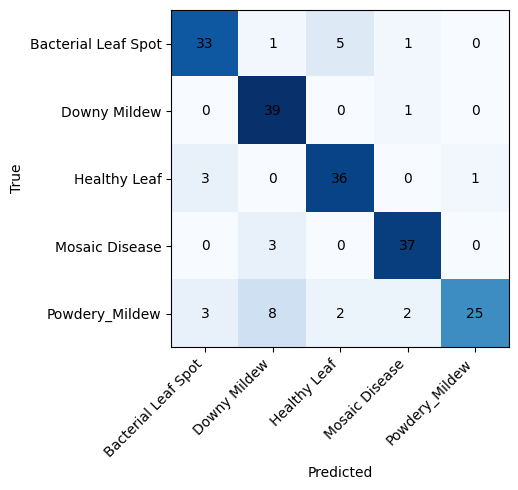

,0
Model,DualFusion-CBAM-Stochastic
Reference,[9]
Seed,42
Split,80/10/10
Split file,/content/drive/MyDrive/pumpkin_runs/split_8010...
Input size,224x224
Epochs,50
Batch size,8
Learning rate,0.00001
Optimizer,"Adam wd=0.0001, StepLR 5/0.1"


In [5]:
model.load_state_dict(torch.load(ckpt)); model.eval()
y_true, y_pred = [], []
with torch.no_grad():
    for x, y in test_loader:
        y_pred += model(x.to(device)).argmax(1).cpu().tolist(); y_true += y.tolist()

acc = float(np.mean(np.array(y_true) == np.array(y_pred)))
prec, rec, f1w, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted')
_, _, f1m, _ = precision_recall_fscore_support(y_true, y_pred, average='macro')
print(f'TEST acc {acc:.4f} | weighted precision {prec:.4f} recall {rec:.4f} | macro F1 {f1m:.4f}   (paper [9]: 96.0% / F1 0.96)')
print(classification_report(y_true, y_pred, target_names=classes, digits=4))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(6, 5)); ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(5)); ax.set_yticks(range(5)); ax.set_xticklabels(classes, rotation=45, ha='right'); ax.set_yticklabels(classes)
for i in range(5):
    for j in range(5): ax.text(j, i, cm[i, j], ha='center', va='center')
ax.set_xlabel('Predicted'); ax.set_ylabel('True'); plt.tight_layout(); plt.savefig(f'{OUT}/cm_{RUN}.png', dpi=150); plt.show()

row = {'Model': 'DualFusion-CBAM-Stochastic', 'Reference': '[9]', 'Seed': SEED, 'Split': '80/10/10', 'Split file': split_file,
       'Input size': '224x224', 'Epochs': EPOCHS, 'Batch size': BS, 'Learning rate': LR,
       'Optimizer': f'Adam wd={WD}, StepLR {STEP}/{GAMMA}', 'Augmentation': 'None',
       'Best val acc': round(best_val, 4), 'Test acc': round(acc, 4), 'Macro F1': round(f1m, 4),
       'Params (M)': round(n_params, 2), 'Train time (min)': round(train_min, 1),
       'Notebook file': 'pumpkin_dualfusion_cbam_stochastic.ipynb', 'Checkpoint path': ckpt}
log = f'{OUT}/run_log.csv'
pd.DataFrame([row]).to_csv(log, mode='a', header=not os.path.exists(log), index=False)
pd.DataFrame([row]).T